# Low-default portfolios: the most prudent estimate of Pluto and Tasche

**Question:** What PD can a low-default portfolio defend for each grade when its best grade shows no default at all, how much does default correlation raise it, and how much capital does prudence add to an expert's figures?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 02 of this topic (intervals on a thin grade)
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- explain the most prudent estimate: a PD for each grade as an upper confidence bound, under the assumption that every worse grade has the same PD, and say why it needs pooled counts;
- compute the bound for independent defaults and read it against the closed form for zero defaults and against SciPy's Beta quantile;
- add default correlation with the one-factor model, and read how much the bound rises;
- scale the bounds to a portfolio target, and carry a multi-year cohort with serially correlated factors;
- recompute the 204 printed cells of Pluto and Tasche's Tables 1 to 14, list the cells that deviate and say why;
- read what a known-truth study says about coverage, and what the bounds cost in capital.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.engines import low_default as ld
from riskvalidation.regulatory import irb
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Four committed files of case C05, the second half of the case: low-default portfolios (licence class `derived-only` for the printed tables of Pluto and Tasche, 2005; https://arxiv.org/abs/cond-mat/0411699):

- `data/derived/C05/ldp-published.json`: the example of the paper, three grades A, B and C with 100, 400 and 300 obligors and 0, 2 and 1 defaults, the bounds at six confidence levels, the 204 printed cells of Tables 1 to 14 with the recomputation (`outputs.golden`), the committed tests of a hypothetical expert's PDs, and the capital impact.
- `data/derived/C05/ldp-sim-0.json`, `ldp-sim-1.json` and `ldp-sim-3.json`: the same portfolio in a year generated by a Vasicek model with known PDs (0.05%, 0.10% and 0.20%, correlation 12%) with no default, one and three, each with the coverage of the bounds and the size and power of the tests measured over 20,000 generated years.

The grade counts here are the paper's own example, public in the paper.

The next cell loads the files and prints the example.

In [2]:
# Load the four artifacts (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
C05 = ROOT / "data" / "derived" / "C05"
load = lambda name: json.loads((C05 / name).read_text(encoding="utf-8"))
published = load("ldp-published.json")
sims = {k: load(f"ldp-sim-{k}.json") for k in (0, 1, 3)}
out = published["outputs"]
grades, N, few = out["grades"], tuple(out["obligors"]), tuple(out["defaults"])
gammas, rho = out["gammas"], out["rho"]

print("grades:", grades, "| obligors:", N, "| defaults:", few)
print("confidence levels:", gammas, "| asset correlation of the paper:", rho)
print("hypothetical expert PDs:", out["expert_pd"])

grades: ['A', 'B', 'C'] | obligors: (100, 400, 300) | defaults: (0, 2, 1)
confidence levels: [0.5, 0.75, 0.9, 0.95, 0.99, 0.999] | asset correlation of the paper: 0.12
hypothetical expert PDs: [0.0003, 0.0005, 0.001]


## Method

### Step 1: the most prudent estimate, independent defaults

With three defaults in 800 obligors a portfolio has a default rate, but the individual grades do not: A has none. Pluto and Tasche (2005) ask for the PD of each grade as an **upper confidence bound** at level $\gamma$, under the *most prudent* assumption compatible with the ordering of the grades: every grade from $i$ downward has the same PD, so the obligors and the defaults of grades $i, \dots, k$ are pooled. With $N$ pooled obligors and $D$ pooled defaults, independent defaults, the bound $p$ solves

$$P\bigl(\mathrm{Binomial}(N, p) \le D\bigr) = 1 - \gamma$$

(the Clopper-Pearson upper bound). For $D = 0$ it has the closed form $p = 1 - (1 - \gamma)^{1/N}$. The engine's `most_prudent_pd` returns the bounds and the pooled counts. Two independent checks apply: the closed form for a case with no default, and the Beta distribution quantile of SciPy, since the binomial tail and the Beta distribution function are the same function.

The next cell prints the pooled counts and the bounds at 90%, with SciPy's Beta quantile beside the engine's bound, and the zero-default case beside its closed form.

In [3]:
# The bounds of the example at 90%, SciPy's Beta quantile, and the closed form for zero defaults
gamma = 0.9
bound = ld.most_prudent_pd(N, few, gamma)
pooled_n, pooled_d = bound["pooled_obligors"], bound["pooled_defaults"]
beta = [stats.beta.ppf(gamma, d + 1, n - d) for n, d in zip(pooled_n, pooled_d)]
zero = ld.most_prudent_pd(N, (0, 0, 0), gamma)
closed = [1 - (1 - gamma) ** (1 / n) for n in zero["pooled_obligors"]]

print(f"{'grade':8s}{'pooled N':>14s}{'pooled D':>14s}{'engine':>12s}{'Beta':>10s}")
for g in range(3):
    print(f"{grades[g]:8s}{pooled_n[g]:14d}{pooled_d[g]:14d}{100 * bound['pd'][g]:11.4f}%{100 * beta[g]:9.4f}%")
print("zero defaults, engine:", [f"{100 * p:.4f}%" for p in zero["pd"]])
print("zero defaults, closed form:", [f"{100 * p:.4f}%" for p in closed])

grade         pooled N      pooled D      engine      Beta
A                  800             3     0.8332%   0.8332%
B                  700             3     0.9519%   0.9519%
C                  300             1     1.2903%   1.2903%
zero defaults, engine: ['0.2874%', '0.3284%', '0.7646%']
zero defaults, closed form: ['0.2874%', '0.3284%', '0.7646%']


The bounds rise from A to C, as the construction guarantees, and every grade, even A with no default, gets a positive PD that rests on all 800 obligors: 0.8332% for A, 0.9519% for B and 1.2903% for C at 90%. The engine's bound and SciPy's Beta quantile are the same number, since the binomial tail and the Beta distribution function are the same function, and with no default the engine equals the closed form. The cost is conservatism: the bounds say how high the PD can be at that confidence, not what it probably is. The numbers do not yet reflect that obligors default together, which is the next step.

### Step 2: default correlation

Defaults of obligors that share an economy are correlated, and the binomial law then understates the spread of the number of defaults. Pluto and Tasche (section 4) use the one-factor model: each obligor defaults when $\sqrt{\rho}\,Y + \sqrt{1-\rho}\,\xi$ falls below $\Phi^{-1}(p)$, with a common factor $Y$, so given $Y = y$ the default probability is $p(y) = \Phi\bigl((\Phi^{-1}(p) - \sqrt{\rho}\,y)/\sqrt{1-\rho}\bigr)$ and the bound solves

$$1 - \gamma = \int \varphi(y)\, P\bigl(\mathrm{Binomial}(N, p(y)) \le D\bigr)\, dy$$

The engine integrates by Gauss-Hermite quadrature. The paper takes $\rho = 12\%$, the minimum Basel corporate correlation (CRE31).

The next cell computes the independent and the correlated bounds at the six levels and prints how many times higher the correlated ones are.

In [4]:
# The independent and the correlated bounds at the six levels, and their ratio
independent = np.array([ld.most_prudent_pd(N, few, g)["pd"] for g in gammas])
correlated = np.array([ld.most_prudent_pd(N, few, g, rho)["pd"] for g in gammas])

head = "".join(f"{g + ' (%)':>12s}" for g in grades) + "".join(f"{g + ' ratio':>12s}" for g in grades)
print(f"{'level':>7s}" + head)
for gm, c, i in zip(gammas, correlated, independent):
    print(f"{gm:7.3f}" + "".join(f"{100 * v:11.4f}%" for v in c) + "".join(f"{v:12.2f}" for v in c / i))

  level       A (%)       B (%)       C (%)     A ratio     B ratio     C ratio
  0.500     0.7106%     0.8006%     0.8352%        1.55        1.53        1.49
  0.750     1.4149%     1.5808%     1.7536%        2.22        2.17        1.96
  0.900     2.4910%     2.7617%     3.1813%        2.99        2.90        2.47
  0.950     3.4121%     3.7653%     4.4078%        3.53        3.41        2.80
  0.990     5.8758%     6.4272%     7.6714%        4.70        4.50        3.50
  0.999    10.0754%    10.9121%    13.1333%        6.21        5.89        4.33


The next cell draws the independent bounds (solid) and the correlated ones (dashed) of the three grades against the confidence level, with the expert's PDs as dotted lines.

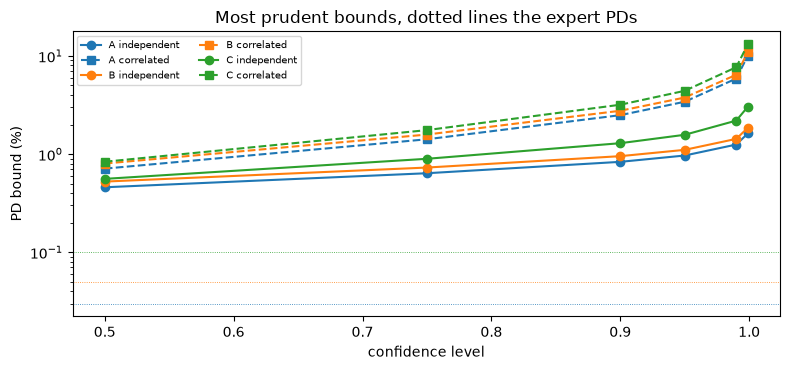

In [5]:
# Draw the independent and correlated bounds against the confidence level, with the expert PDs
fig, ax = plt.subplots(figsize=(8, 3.8))
for j, color in enumerate(("tab:blue", "tab:orange", "tab:green")):
    ax.plot(gammas, 100 * independent[:, j], color=color, marker="o", label=f"{grades[j]} independent")
    ax.plot(gammas, 100 * correlated[:, j], color=color, marker="s", linestyle="--",
            label=f"{grades[j]} correlated")
    ax.axhline(100 * out["expert_pd"][j], color=color, linewidth=0.6, linestyle=":")
ax.set_yscale("log")
ax.set_xlabel("confidence level")
ax.set_ylabel("PD bound (%)")
ax.set_title("Most prudent bounds, dotted lines the expert PDs")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

With the paper's asset correlation of 12% the 90% bounds are 2.4910%, 2.7617% and 3.1813%, about three times the independent ones for A and B and 2.5 times for C, and at 99.9% grade A's bound is 10.0754%, 6.2 times its independent bound. The correlated lines lie far above the independent ones at high confidence and about 1.5 times above them at 50%, so the confidence level and the correlation work together. The three expert PDs sit below every bound drawn, by a factor of 13 to 28 against the independent bounds at 90%, which is the sense in which the expert's figures are not prudent; whether they are wrong is a statistical question that Step 7 puts to the data. The figure does not choose the confidence level: the paper calls the choice arbitrary and finds levels below 95% more appropriate.

### Step 3: scaling to a portfolio target

The bounds of the three grades are all upper bounds: their weighted average is far above the portfolio's own default rate. Section 5 of the paper scales them with one common factor $K$, keeping their order and their ratios, so that the obligor-weighted average equals a target $T$:

$$K = \frac{T \sum_i n_i}{\sum_i n_i\, \hat p_i}, \qquad p_i^{\mathrm{scaled}} = K\, \hat p_i$$

(equations 5.1 and 5.2). Two targets are used: the portfolio's observed default rate (the *central tendency*, needs at least one default) and the most prudent bound of the whole portfolio, which is the best grade's bound (the *upper bound*, the paper's proposal). Scaling gives up the reading of the numbers as confidence bounds.

The next cell calls `most_prudent_pd_scaled` for both targets at 90% and prints the target, the factor K, the scaled PDs and the weighted average they give.

In [6]:
# Scale the 90% bounds to the two targets and check the weighted average they give
weights = np.array(N, dtype=float)
for target in ("upper_bound", "central_tendency"):
    s = ld.most_prudent_pd_scaled(N, few, 0.9, target=target)
    average = float(np.sum(weights * s["pd"]) / weights.sum())
    print(f"{target:18s} T = {100 * s['target']:.4f}% | K = {s['k']:.4f} | weighted average {100 * average:.4f}%")
    print(f"{'':18s} scaled PDs:", [f"{100 * v:.4f}%" for v in s["pd"]])
print("unscaled 90% bounds:", [f"{100 * v:.4f}%" for v in bound["pd"]])

upper_bound        T = 0.8332% | K = 0.7831 | weighted average 0.8332%
                   scaled PDs: ['0.6524%', '0.7454%', '1.0104%']
central_tendency   T = 0.3750% | K = 0.3525 | weighted average 0.3750%
                   scaled PDs: ['0.2937%', '0.3355%', '0.4548%']
unscaled 90% bounds: ['0.8332%', '0.9519%', '1.2903%']


The scaled bounds sit between the portfolio's default rate and the raw bounds: the common factor K is below one for both targets here, 0.7831 for the upper bound and 0.3525 for the central tendency, and the weighted average equals the target to the digits printed. The order of the grades is kept and so are the ratios between them, which is the purpose of one common factor. Scaling gives up the reading of the numbers as confidence bounds: a scaled PD is a calibration to a target, not a statement about how high the true PD can be.

### Step 4: a cohort followed for several years

With a cohort observed for $T$ years the defaults are those of the whole period, and the factor of each year is correlated with the next. Section 6 of the paper takes standard normal factors $S_t$ with correlation $\theta^{|s-t|}$; the obligor defaults in year $t$ when $\sqrt{\rho}\,S_t + \sqrt{1-\rho}\,\xi_{it}$ first falls below $\Phi^{-1}(p)$, so $p$ is a long-run one-year PD. Given the factors an obligor defaults within the period with probability $1 - \prod_t (1 - p(S_t))$ (6.7), and the bound is the largest $p$ with $P[\text{at most } D \text{ defaults}] \ge 1 - \gamma$ (6.6, 6.8b). The expectation over the factors is a Monte Carlo average, with the same paths for every $p$. The cell uses the paper's setting ($\rho = 12\%$, $\theta = 30\%$, five years) with 100,000 paths and seed 5, the setting of the committed run, for the example and for the same portfolio with no default.

In [7]:
# Multi-period bounds at 90% and 99% for the example and for no defaults, against the one-year bounds
settings = dict(rho=0.12, theta=0.3, years=5, n_sim=100_000, seed=5)
print("settings of the paper and the run:", settings)
print(f"{'':28s}" + "".join(f"{g:>10s}" for g in grades))
for gm in (0.9, 0.99):
    for label, d in (("example", few), ("no defaults", (0, 0, 0))):
        multi = ld.most_prudent_pd_multiperiod(N, d, gm, **settings)["pd"]
        one = ld.most_prudent_pd(N, d, gm)["pd"]
        print(f"{label + ' ' + str(gm) + ' 5y':28s}" + "".join(f"{100 * v:9.4f}%" for v in multi))
        print(f"{label + ' ' + str(gm) + ' 1y':28s}" + "".join(f"{100 * v:9.4f}%" for v in one))

settings of the paper and the run: {'rho': 0.12, 'theta': 0.3, 'years': 5, 'n_sim': 100000, 'seed': 5}
                                     A         B         C
example 0.9 5y                 0.3241%   0.3647%   0.4425%
example 0.9 1y                 0.8332%   0.9519%   1.2903%
no defaults 0.9 5y             0.1054%   0.1189%   0.2552%
no defaults 0.9 1y             0.2874%   0.3284%   0.7646%
example 0.99 5y                0.6810%   0.7608%   0.9858%
example 0.99 1y                1.2501%   1.4278%   2.1921%
no defaults 0.99 5y            0.2850%   0.3193%   0.6570%
no defaults 0.99 1y            0.5740%   0.6557%   1.5233%


The five-year bounds are lower than the one-year ones: at 90% the example gives 0.3241%, 0.3647% and 0.4425% against 0.8332%, 0.9519% and 1.2903%, and with no default 0.1054%, 0.1189% and 0.2552% against 0.2874%, 0.3284% and 0.7646%. Five years of observation add exposure that a single year does not have, so the same few defaults weigh less per obligor-year, even with factors correlated from one year to the next. The numbers come from a Monte Carlo average with the same paths for every candidate PD, so they carry a small sampling error that the seed fixes. They are not comparable with a one-year PD in how it is used: a multi-year bound is a long-run one-year PD.

### Step 5: the 204 printed cells

Pluto and Tasche print fourteen tables for this example: Tables 1 to 3 the bounds of A, B and C with no default, Tables 4 to 6 the same with the defaults of the example, Tables 7 and 8 the correlated bounds for the two cases, Tables 9 and 10 the bounds scaled to the central tendency (independent and correlated), Tables 11 and 12 scaled to the upper bound, and Tables 13 and 14 the multi-period bounds for the two cases. Each has six confidence levels. The artifact commits every printed cell (`outputs.golden.cells`).

The first cell below recomputes the fourteen tables with the engine and keeps each value in percent (K unitless); the multi-period tables use the Monte Carlo of Step 4, so it takes a few seconds. The second cell rounds each value to the printed precision, compares it with the paper's cell and counts, per table, the cells that agree.

In [8]:
# Recompute the fourteen printed tables: independent, correlated, scaled and multi-period
zero_d = (0, 0, 0)
fresh = {}
for gi, gm in enumerate(gammas):
    for table, d, rr in ((1, zero_d, 0.0), (4, few, 0.0), (7, zero_d, rho), (8, few, rho)):
        pds = ld.most_prudent_pd(N, d, gm, rr)["pd"]
        for j, row in enumerate(("pa", "pb", "pc")):
            fresh[(table + j if table in (1, 4) else table, row, gi)] = 100 * pds[j]
    scaled_specs = ((9, 0.0, "central_tendency"), (10, rho, "central_tendency"),
                    (11, 0.0, "upper_bound"), (12, rho, "upper_bound"))
    for table, rr, target in scaled_specs:
        s = ld.most_prudent_pd_scaled(N, few, gm, rr, target=target)
        fresh[(table, "k", gi)] = s["k"]
        for j, row in enumerate(("pa,scaled", "pb,scaled", "pc,scaled")):
            fresh[(table, row, gi)] = 100 * s["pd"][j]
    for table, d in ((13, zero_d), (14, few)):
        multi = ld.most_prudent_pd_multiperiod(N, d, gm, **settings)["pd"]
        for j, row in enumerate(("pa", "pb", "pc")):
            fresh[(table, row, gi)] = 100 * multi[j]
print("recomputed cells:", len(fresh))

recomputed cells: 204


The next cell rounds each recomputed value to the printed precision (two decimals in percent, K as printed), takes its gap to the paper's cell and counts the cells that agree, table by table.

In [9]:
# Round each recomputed cell to the printed precision, compare it with the paper's cell, and count by table
cells = out["golden"]["cells"]
level_of = {g: i for i, g in enumerate(gammas)}
gaps = [round(round(fresh[(c["table"], c["row"], level_of[c["gamma"]])], 2) - c["printed"], 4) for c in cells]
per_table = [[g for c, g in zip(cells, gaps) if c["table"] == t] for t in range(1, 15)]
agree = [sum(g == 0 for g in gs) for gs in per_table]

print("printed cells:", len(cells))
print(f"{'table':>7s}{'cells':>8s}{'agree':>10s}{'largest gap':>16s}")
for t, (gs, a) in enumerate(zip(per_table, agree), start=1):
    print(f"{t:7d}{len(gs):8d}{a:10d}{max(abs(g) for g in gs):16.2f}")
off = [g for g in gaps if g != 0]
print("cells that agree to the printed digit:", len(cells) - len(off), "| that do not:", len(off))
print("by more than one unit of the last digit:", sum(abs(g) > 0.01 for g in gaps),
      "| printed above the recomputed value:", sum(g < 0 for g in off), "of", len(off))

printed cells: 204
  table   cells     agree     largest gap
      1       6         6            0.00
      2       6         6            0.00
      3       6         6            0.00
      4       6         5            0.01
      5       6         6            0.00
      6       6         6            0.00
      7      18        15            0.01
      8      18         6            0.01
      9      24        23            0.01
     10      24        21            0.01
     11      24        13            0.02
     12      24        12            0.10
     13      18         3            0.04
     14      18         1            0.05
cells that agree to the printed digit: 129 | that do not: 75
by more than one unit of the last digit: 15 | printed above the recomputed value: 68 of 75


The next cell draws, for each of the fourteen tables, how many printed cells the engine reproduces to the printed digit and how many it does not.

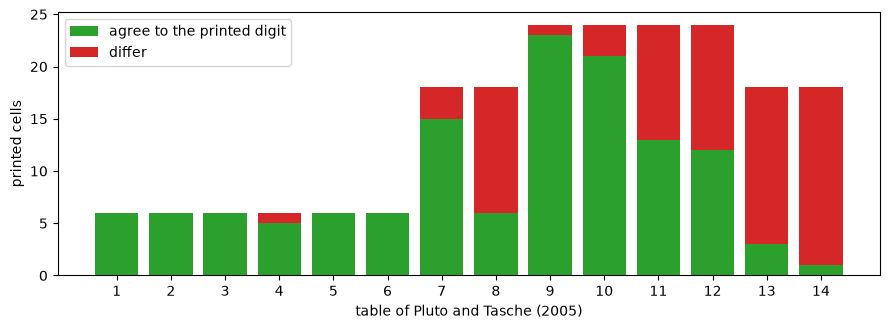

In [10]:
# Draw, by table, the cells that agree with the print and the cells that do not
counts = [len(gs) for gs in per_table]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(range(1, 15), agree, color="tab:green", label="agree to the printed digit")
ax.bar(range(1, 15), [c - a for c, a in zip(counts, agree)], bottom=agree, color="tab:red", label="differ")
ax.set_xticks(range(1, 15))
ax.set_xlabel("table of Pluto and Tasche (2005)")
ax.set_ylabel("printed cells")
ax.legend()
fig.tight_layout()
plt.show()

Of the 204 printed cells the engine reproduces 129 to the printed digit. Sixty differ by one unit of the last printed digit, which a rounding of the paper's own arithmetic explains, and 15 by more: Table 11 at 75% and 95%, the multi-period Tables 13 and 14 and one cell of Table 12 (B at 99.9%, printed 9.54 against 9.44). The committed notes name the groups. In Table 4 the paper's 0.65% is the bound at 76.3%, not at 75%, where the exact bound is 0.638%, and Table 11 scales with that 0.65%. Every printed cell of Table 8 lies at or above the exact bound. The multi-period tables come from a Monte Carlo that the engine checks by a deterministic quadrature, with the print above it. In 68 of the 75 cells that differ the print is the larger. A recomputation that does not reproduce a print is reported with its cell, not adjusted.

### Step 6: what a known truth says

The three `ldp-sim` files give the same portfolio in generated years where the true PDs are known: 0.05%, 0.10% and 0.20% with a correlation of 12%, in a year with no default, with one and with three. Two readings follow. The next cell applies the engine to each generated year and sets the 90% bound beside the truth, and reads from the committed study of 20,000 generated years the coverage of the bound (the share of years in which it is at least the true PD) of grade B and the median ratio of the bound to the truth.

In [11]:
# The 90% bound of each generated year beside the true PDs, and the committed coverage of grade B
truth = np.array(sims[0]["outputs"]["true_pd"])
print("true PDs:", [f"{100 * v:.2f}%" for v in truth],
      "| generated years in the study:", sims[0]["outputs"]["known_truth"]["years"])
for k, doc in sims.items():
    d = tuple(doc["outputs"]["defaults"])
    pds = ld.most_prudent_pd(N, d, 0.9)["pd"]
    print("year with defaults", d, "| 90% bound:", [f"{100 * v:.3f}%" for v in pds],
          "| bound / truth:", [round(float(v), 1) for v in pds / truth])
cover = sims[0]["outputs"]["known_truth"]["coverage"]
levels = [r["gamma"] for r in cover["independent"]["B"]]
print("grade B: coverage, then median bound / true PD")
print(f"{'level':>7s}" + "".join(f"{kind:>16s}" for kind in cover))
for i, lv in enumerate(levels):
    print(f"{lv:7.2f}" + "".join(f"{cover[kind]['B'][i]['coverage']:16.4f}" for kind in cover))
for i, lv in enumerate(levels):
    print(f"{lv:7.2f}" + "".join(f"{cover[kind]['B'][i]['ratio_median']:16.2f}" for kind in cover))

true PDs: ['0.05%', '0.10%', '0.20%'] | generated years in the study: 20000
year with defaults (0, 0, 0) | 90% bound: ['0.287%', '0.328%', '0.765%'] | bound / truth: [5.7, 3.3, 3.8]
year with defaults (0, 0, 1) | 90% bound: ['0.485%', '0.555%', '1.290%'] | bound / truth: [9.7, 5.5, 6.5]
year with defaults (0, 0, 3) | 90% bound: ['0.833%', '0.952%', '2.213%'] | bound / truth: [16.7, 9.5, 11.1]
grade B: coverage, then median bound / true PD
  level     independent      correlated          scaledscaled_correlated
   0.50          0.4541          1.0000          0.4645          1.0000
   0.75          1.0000          1.0000          1.0000          1.0000
   0.90          1.0000          1.0000          1.0000          1.0000
   0.95          1.0000          1.0000          1.0000          1.0000
   0.99          1.0000          1.0000          1.0000          1.0000
   0.50            0.99            1.73            0.58            1.09
   0.75            1.98            4.51            1

The next cell draws the coverage of grade B for the four kinds of bound, and the median ratio of the bound to the true PD.

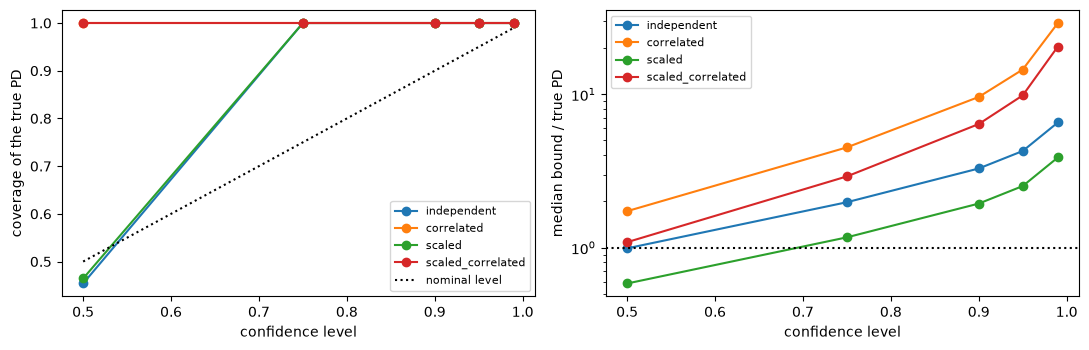

In [12]:
# Draw the coverage of grade B (left) and the median bound over the true PD (right), by confidence level
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
for kind in cover:
    left.plot(levels, [r["coverage"] for r in cover[kind]["B"]], marker="o", label=kind)
    right.plot(levels, [r["ratio_median"] for r in cover[kind]["B"]], marker="o", label=kind)
left.plot(levels, levels, color="black", linestyle=":", label="nominal level")
right.axhline(1.0, color="black", linestyle=":")
right.set_yscale("log")
left.set_ylabel("coverage of the true PD")
right.set_ylabel("median bound / true PD")
for ax in (left, right):
    ax.set_xlabel("confidence level")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The independent bound of grade B covers the true PD in 45.4% of the generated years at 50% and in every year from 75% up, with a median bound of 0.99 times the truth at 50% and 6.56 times at 99%. The scaled estimate covers 46.5% at 50%, because 53.5% of the generated years have no default at all and the scaled estimate then has nothing to scale; the correlated bounds cover everything from 50% up, 1.73 times the truth at 50% and 29.2 times at 99%. The bounds are conservative by construction, and the scaled ones give up coverage for a closer level. The figure shows the price of prudence in the units of the truth, which is how much further than the true PD the validator is asked to carry the figure.

### Step 7: the expert's PDs, and what the bounds cost in capital

The example has a hypothetical expert who says 0.03%, 0.05% and 0.10%. The artifact commits the tests of those PDs against the data: the Jeffreys test by grade and for the portfolio, the binomial test, and the binomial test with asset correlation. The bounds are inputs to capital, so the second cell below recomputes the average IRB risk weight (Basel III corporate, LGD 45%, maturity 2.5, PD floor 0.05%; https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27) of the obligor-weighted portfolio under the expert PDs and under the bounds at 75%.

In [13]:
# Read the committed tests of the expert's PDs
print("baked by riskvalidation", published["provenance"]["riskvalidation_version"],
      "| installed", md.version("riskvalidation"))
print(f"{'test':22s}{'segment':>12s}{'p':>10s}{'light':>8s}")
for t in published["tests"]:
    print(f"{t['test_id']:22s}{str(t['segment']):>12s}{t['p_value']:10.4f}{t['light']:>8s}")

baked by riskvalidation 1.0.1 | installed 1.0.1
test                       segment         p   light
pd.jeffreys                      A    0.1938   green
pd.jeffreys                      B    0.0047     red
pd.jeffreys                      C    0.1035   green
pd.jeffreys              portfolio    0.0062     red
pd.binomial              portfolio    0.0167   amber
pd.binomial_vasicek      portfolio    0.0507   green


The next cell prices the expert's PDs and the 75% bounds, independent, correlated and scaled, in average risk weight.

In [14]:
# Average IRB risk weight of the portfolio under the expert PDs and under the 75% bounds
cfg = out["irb"]
weights_n = np.array(N, dtype=float)
scenarios = {
    "expert PDs (floored at 0.05%)": out["expert_pd"],
    "most prudent at 75%": ld.most_prudent_pd(N, few, 0.75)["pd"],
    "most prudent at 75%, correlation 12%": ld.most_prudent_pd(N, few, 0.75, rho)["pd"],
    "scaled to the portfolio bound at 75%": ld.most_prudent_pd_scaled(N, few, 0.75, target="upper_bound")["pd"],
}
average = {}
for label, pds in scenarios.items():
    rw = [irb.capital_requirement(cfg["asset_class"], float(p), cfg["lgd"], maturity=cfg["maturity"],
                                  regime=cfg["regime"]).risk_weight for p in pds]
    average[label] = float(np.sum(weights_n * np.array(rw)) / weights_n.sum())
    print(f"{label:68s}{100 * average[label]:8.1f}%")

expert PDs (floored at 0.05%)                                           23.4%
most prudent at 75%                                                     83.8%
most prudent at 75%, correlation 12%                                   108.1%
scaled to the portfolio bound at 75%                                    77.2%


The next cell draws the four average risk weights.

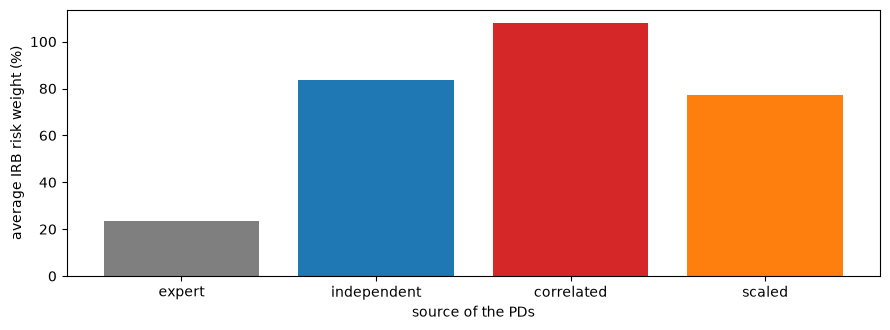

In [15]:
# Draw the average IRB risk weight under the expert PDs and under the three kinds of bound
fig, ax = plt.subplots(figsize=(9, 3.4))
short = ["expert", "independent", "correlated", "scaled"]
ax.bar(short, [100 * v for v in average.values()], color=["tab:gray", "tab:blue", "tab:red", "tab:orange"])
ax.set_xlabel("source of the PDs")
ax.set_ylabel("average IRB risk weight (%)")
fig.tight_layout()
plt.show()

The hypothetical expert's PDs are rejected by the Jeffreys test for grade B (p = 0.0047, red) and for the portfolio (p = 0.0062, red), amber by the binomial test (p = 0.0167) and green once correlation is allowed (p = 0.0507): whether the figures are wrong depends on whether defaults are independent. In capital the gap is large whichever test is used. The expert's PDs give an average risk weight of 23.4%, the 75% bounds 83.8%, the correlated ones 108.1% and the scaled ones 77.2%. The estimation principle is worth tens of points of risk weight, and the figure shows that the scaling, which gives up the reading as a confidence bound, takes off only about a tenth of the extra capital the raw bound asks for.

## Results

**Answer:** a low-default portfolio can defend a positive PD for every grade, even one with no default, as an upper confidence bound on the pool of that grade and all worse ones: at 90% the example's three defaults in 800 obligors give 0.8332% for A, 0.9519% for B and 1.2903% for C. The paper's asset correlation of 12% raises them to 2.4910%, 2.7617% and 3.1813%, and prudence costs capital: the hypothetical expert's PDs give an average IRB risk weight of 23.4%, against 83.8% with the 75% bounds, 108.1% with the correlated ones and 77.2% with the scaled ones. The expert's PDs are rejected for grade B (Jeffreys p = 0.0047) and for the portfolio (p = 0.0062), and accepted once correlation is allowed (p = 0.0507).

- **Scaling.** Scaled to the best grade's bound (the paper's proposal) the 90% bounds are a factor K = 0.7831 of the raw ones; scaled to the portfolio's observed default rate of 0.3750% the factor is K = 0.3525. In both cases the weighted average equals the target and the order is kept.
- **Years of observation.** The five-year bounds with 12% asset correlation and 30% year-to-year factor correlation are lower than the one-year ones: at 90%, 0.3241%, 0.3647% and 0.4425% against 0.8332%, 0.9519% and 1.2903% for the example.
- **The 204 printed cells.** The engine reproduces 129 to the printed digit. Sixty differ by one unit of the last printed digit and 15 by more, and where they differ the print is above the recomputation in 68 of 75 cells.
- **What a known truth says.** The independent bound of grade B covers the true PD in 45.4% of the generated years at 50% and in every year from 75%, with a median bound of 6.56 times the truth at 99%.

What this notebook does not show: how a validator chooses a confidence level (the paper calls the choice arbitrary and says levels below 95% seem more appropriate), or the PD curve of a rated portfolio (notebooks 05 and 09).

## Summary

- With few or no defaults a grade's PD is an upper confidence bound on the pool of that grade and all worse ones; the bound is monotone across grades and positive even with no default.
- Default correlation raises the bound several times; scaling to a portfolio target lowers it and gives up its reading as a bound; several years of observation lower it.
- The 204 printed cells of the paper are recomputed: 129 to the digit, the rest reported with their gap and the reason the committed notes give.
- A bound is conservative by construction: on known truth it covers in every year from 75% and is several times the true PD.

**What to try next.** Change the number of defaults of grade A in Step 1 from 0 to 1 and watch the three bounds move; then read notebook 07.

## References

- Pluto, K. and Tasche, D. (2005), Estimating probabilities of default for low default portfolios, in Engelmann and Rauhmeier (eds), The Basel II Risk Parameters, Springer; arXiv cond-mat/0411699, sections 2 to 6, Tables 1 to 14. https://arxiv.org/abs/cond-mat/0411699
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2), for the Clopper-Pearson and Jeffreys bounds. https://doi.org/10.1214/ss/1009213286
- BCBS, Basel Framework, CRE32, IRB approach: risk-weighted asset calculation. https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- Vasicek, O. (2002), Loan portfolio value, Risk, December 2002, 160-162, for the one-factor model.